Epoch [100/10000], Loss: 0.1974
Epoch [200/10000], Loss: 0.1655
Epoch [300/10000], Loss: 0.1554
Epoch [400/10000], Loss: 0.1503
Epoch [500/10000], Loss: 0.1465
Epoch [600/10000], Loss: 0.1433
Epoch [700/10000], Loss: 0.1404
Epoch [800/10000], Loss: 0.1378
Epoch [900/10000], Loss: 0.1354
Epoch [1000/10000], Loss: 0.1333
Epoch [1100/10000], Loss: 0.1313
Epoch [1200/10000], Loss: 0.1295
Epoch [1300/10000], Loss: 0.1279
Epoch [1400/10000], Loss: 0.1264
Epoch [1500/10000], Loss: 0.1251
Epoch [1600/10000], Loss: 0.1238
Epoch [1700/10000], Loss: 0.1227
Epoch [1800/10000], Loss: 0.1216
Epoch [1900/10000], Loss: 0.1207
Epoch [2000/10000], Loss: 0.1198
Epoch [2100/10000], Loss: 0.1189
Epoch [2200/10000], Loss: 0.1181
Epoch [2300/10000], Loss: 0.1174
Epoch [2400/10000], Loss: 0.1167
Epoch [2500/10000], Loss: 0.1161
Epoch [2600/10000], Loss: 0.1155
Epoch [2700/10000], Loss: 0.1149
Epoch [2800/10000], Loss: 0.1144
Epoch [2900/10000], Loss: 0.1139
Epoch [3000/10000], Loss: 0.1134
Epoch [3100/10000],

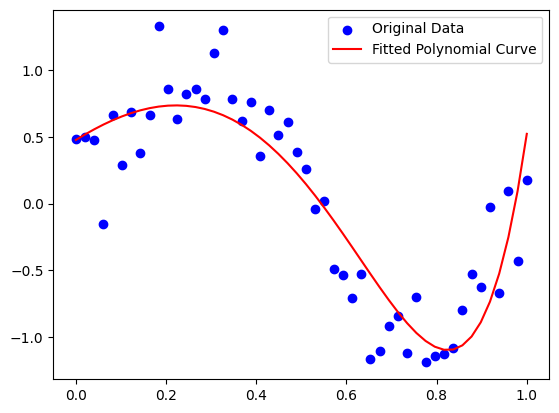

In [2]:
import matplotlib.pyplot as plt
import torch

def create_toy_data(func, sample_size, std, domain=[0, 1]):
    x = torch.linspace(domain[0], domain[1], sample_size)
    y = func(x) + torch.randn(x.shape) * std
    return x, y

# Sinusoidal function
def sinusoidal(x):
    return torch.sin(2 * torch.pi * x)

# Step 1: Generate synthetic dataset
torch.manual_seed(42)

x_train, y_train = create_toy_data(sinusoidal, 50, 0.25)
x_train= x_train.reshape(-1,1)
y_train= y_train.reshape(-1,1)

# Step 2: Create polynomial features (degree 2)
def polynomial_features(x, degree):
    """Generate polynomial features manually"""
    x_poly = torch.cat([x**i for i in range(1, degree + 1)], dim=1)
    return x_poly

degree = 9
x_poly = polynomial_features(x_train, degree)

# Step 3: Initialize parameters (weights and bias)
# Manually initialize the weights and bias
weights = torch.randn(degree, 1, requires_grad=True)
bias = torch.randn(1, requires_grad=True)

# Step 4: Define the model (linear combination of polynomial features)
def model(x_poly, weights, bias):
    """Forward pass for polynomial regression"""
    return x_poly.mm(weights) + bias  # y = W*x + b

# Step 5: Define the Mean Squared Error (MSE) loss function
def mse_loss(y_pred, y_true):
    """Manual MSE loss calculation"""
    return ((y_pred - y_true) ** 2).mean()

# Step 6: Training loop (manual gradient descent)
learning_rate = 0.1
n_epochs = 10000

for epoch in range(n_epochs):
    # Forward pass: Compute predicted y
    y_pred = model(x_poly, weights, bias)

    # Compute the loss
    loss_train = mse_loss(y_pred, y_train)

    # Backward pass: Compute gradients manually using autograd
    loss_train.backward()

    # Update weights and bias manually (gradient descent)
    with torch.no_grad():  # Temporarily stop tracking gradients
        weights -= learning_rate * weights.grad
        bias -= learning_rate * bias.grad

    # Zero gradients after each step
    weights.grad.zero_()
    bias.grad.zero_()

    # Print the loss every 100 epochs
    if (epoch + 1) % 100 == 0:
        print(f'Epoch [{epoch+1}/{n_epochs}], Loss: {loss_train.item():.4f}')

# Step 7: Plot the results
# Evaluate model (no gradients needed)
with torch.no_grad():
    y_pred = model(x_poly, weights, bias)

print(weights, bias)
# Convert to numpy for plotting
x_np = x_train.numpy()
y_np = y_train.numpy()
y_pred_np = y_pred.numpy()

plt.scatter(x_np, y_np, color='blue', label='Original Data')
plt.plot(x_np, y_pred_np, color='red', label='Fitted Polynomial Curve')
plt.legend()
plt.show()